# CSE 3521: Milestone 2 | Feature Engineering (Group Gamma)

Builds our **second** text representation, **TF-IDF**, next to the Bag of Words used in `classical_models.ipynb`, and makes the feature visualizations for the M2 report.

Cleaning, deduplication and the 80/20 split are **identical** to `classical_models.ipynb` (same seed 44), so the two notebooks see exactly the same training and test reviews.

## 1. Load the sample, clean, deduplicate, split (same as classical_models.ipynb)

In [1]:
from pathlib import Path
import html
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'README.md').is_file() and (p / 'data').is_dir())
FIG_DIR = ROOT / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(ROOT / 'data' / 'group_sample_seed44.csv')

def clean_review(value):
    text = html.unescape(str(value))
    text = re.sub(r'<[^>]*>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df = raw.dropna(subset=['Text', 'Score']).copy()
df = df[df['Score'].isin([1, 2, 4, 5])].copy()
df['Text'] = df['Text'].map(clean_review)
df = df[df['Text'].str.len() > 0]
df = df.drop_duplicates(subset=['Text']).copy()
df['Sentiment'] = np.where(df['Score'] <= 2, 'negative', 'positive')

X_train, X_test, y_train, y_test = train_test_split(
    df['Text'], df['Sentiment'], test_size=0.20, random_state=44, stratify=df['Sentiment'])
print('Usable reviews:', len(df), '| train:', len(X_train), '| test:', len(X_test))

Usable reviews: 42848 | train: 34278 | test: 8570


## 2. Build both representations

Both use unigrams + bigrams and drop terms that appear in fewer than 2 training reviews. Vectorizers are **fit on the training set only**, so nothing from the test set leaks into the vocabulary or the IDF weights.

* **Bag of Words**: each feature is the raw count of a term in the review.
* **TF-IDF**: count × inverse document frequency, so terms that appear in almost every review (*the*, *this*, *product*) are down-weighted and rarer, more distinctive terms stand out. `sublinear_tf=True` uses 1 + log(count) so a word repeated 10 times does not count 10× as much. Each review vector is L2-normalised, so long and short reviews are on the same scale.

In [2]:
common = dict(ngram_range=(1, 2), min_df=2, lowercase=True)

# Full vocabulary size before the 50,000 cap, to report in the M2 write-up.
full_vocab = len(CountVectorizer(**common).fit(X_train).vocabulary_)

bow = CountVectorizer(**common, max_features=50000)
X_train_bow = bow.fit_transform(X_train)

tfidf = TfidfVectorizer(**common, max_features=50000, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'Terms with min_df=2 before the cap: {full_vocab:,}')
print(f'BoW vocabulary size:    {len(bow.vocabulary_):,}')
print(f'TF-IDF vocabulary size: {len(tfidf.vocabulary_):,}')
print(f'TF-IDF train matrix: {X_train_tfidf.shape}, non-zero share: '
      f'{X_train_tfidf.nnz / np.prod(X_train_tfidf.shape):.4%}')

Terms with min_df=2 before the cap: 200,860
BoW vocabulary size:    50,000
TF-IDF vocabulary size: 50,000
TF-IDF train matrix: (34278, 50000), non-zero share: 0.1934%


## 3. What TF-IDF changes: the same review under both representations

Compare the highest-weighted terms of one review. BoW ranks by raw count, so filler words win; TF-IDF pushes them down.

In [3]:
example = X_train.iloc[0]
print(example[:300], '...\n')

def top_terms(vectorizer, matrix_row, n=8):
    row = matrix_row.toarray().ravel()
    idx = row.argsort()[::-1][:n]
    names = vectorizer.get_feature_names_out()
    return [(names[i], round(float(row[i]), 3)) for i in idx if row[i] > 0]

print('BoW top terms:   ', top_terms(bow, bow.transform([example])))
print('TF-IDF top terms:', top_terms(tfidf, tfidf.transform([example])))

Why are they still selling this stuff if it can kill your pet!?! Buy treats that are made in the U.S. or make them at home yourself. Don't give this trash to your animals. ...

BoW top terms:    [('your', 2.0), ('this', 2.0), ('are', 2.0), ('if', 1.0), ('or', 1.0), ('your pet', 1.0), ('them at', 1.0), ('to your', 1.0)]
TF-IDF top terms: [('your animals', 0.234), ('the or', 0.229), ('stuff if', 0.219), ('why are', 0.214), ('or make', 0.208), ('don give', 0.202), ('selling this', 0.201), ('kill', 0.19)]


## 4. Top-10 most informative TF-IDF features for each sentiment

For every term we take its **average TF-IDF weight in positive training reviews minus its average in negative training reviews**. A large positive gap means the term is typical of positive reviews; a large negative gap means negative reviews. This needs no trained model, so it describes the feature space itself.

In [4]:
terms = tfidf.get_feature_names_out()
is_pos = (y_train == 'positive').to_numpy()
mean_pos = np.asarray(X_train_tfidf[is_pos].mean(axis=0)).ravel()
mean_neg = np.asarray(X_train_tfidf[~is_pos].mean(axis=0)).ravel()
gap = mean_pos - mean_neg

order = np.argsort(gap)
top_pos = pd.DataFrame({'term': terms[order[::-1][:10]], 'gap': gap[order[::-1][:10]]})
top_neg = pd.DataFrame({'term': terms[order[:10]], 'gap': gap[order[:10]]})
print('Top 10 POSITIVE TF-IDF features:'); print(top_pos.round(4).to_string(index=False))
print('\nTop 10 NEGATIVE TF-IDF features:'); print(top_neg.round(4).to_string(index=False))

Top 10 POSITIVE TF-IDF features:
     term    gap
    great 0.0112
     love 0.0084
     best 0.0066
 the best 0.0063
delicious 0.0050
     good 0.0047
  perfect 0.0043
  this is 0.0042
 is great 0.0041
    loves 0.0041

Top 10 NEGATIVE TF-IDF features:
        term     gap
         not -0.0129
         was -0.0109
        were -0.0062
disappointed -0.0060
         bad -0.0059
       would -0.0055
         had -0.0055
       money -0.0053
      it was -0.0050
          be -0.0046


## 5. Figure: most distinctive TF-IDF terms (diverging bar chart)

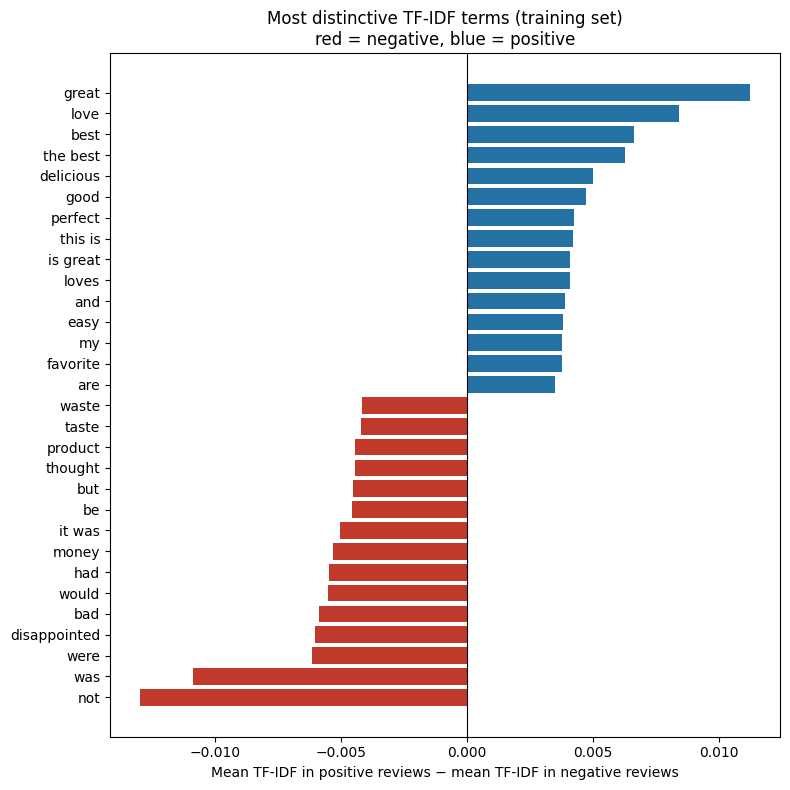

In [5]:
n = 15
idx = np.concatenate([order[:n], order[::-1][:n][::-1]])
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#c0392b' if g < 0 else '#2471a3' for g in gap[idx]]
ax.barh(terms[idx], gap[idx], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Mean TF-IDF in positive reviews − mean TF-IDF in negative reviews')
ax.set_title('Most distinctive TF-IDF terms (training set)\nred = negative, blue = positive')
fig.tight_layout()
fig.savefig(FIG_DIR / 'm2_tfidf_top_terms.png', dpi=170, bbox_inches='tight')
plt.show()

## 6. Figure: 2-D projection of the TF-IDF feature space

TF-IDF vectors have 50,000 dimensions. **Truncated SVD** (PCA for sparse matrices) keeps the 2 directions with the most variance so we can plot them. We plot a random 4,000-review subset of the training set so the dots stay readable.

Variance explained by 2 components: 0.49%


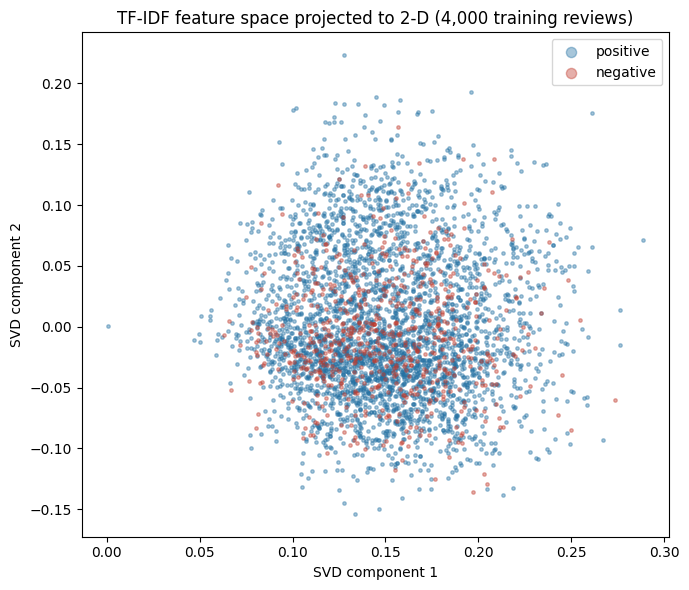

In [6]:
svd = TruncatedSVD(n_components=2, random_state=44)
coords = svd.fit_transform(X_train_tfidf)
print('Variance explained by 2 components:', f'{svd.explained_variance_ratio_.sum():.2%}')

rng = np.random.default_rng(44)
pick = rng.choice(len(coords), size=4000, replace=False)
labels = y_train.to_numpy()[pick]

fig, ax = plt.subplots(figsize=(7, 6))
for label, color in [('positive', '#2471a3'), ('negative', '#c0392b')]:
    m = labels == label
    ax.scatter(coords[pick][m, 0], coords[pick][m, 1], s=6, alpha=0.4, c=color, label=label)
ax.set_xlabel('SVD component 1'); ax.set_ylabel('SVD component 2')
ax.set_title('TF-IDF feature space projected to 2-D (4,000 training reviews)')
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'm2_tfidf_svd_scatter.png', dpi=170, bbox_inches='tight')
plt.show()